# Финансовая отчётность компаний за 2023 год
ТЗ: Найдите в данных минимум три интересные детали – закономерности, неожиданные связи или аномалии:
1. Выведите описательную статистику для датасета
2. Постройте гистограммы для трех колонок, которые, на ваш взгляд, могут содержать полезную информацию. Выясните, есть ли в этих колонках выбросы и аномалии (значения, которые сильно отличаются от остальных значений или кажутся странными/некорректными).
3. Вычислите и визуализируйте матрицу корреляции между всеми 20 колонками. Между какими колонками имеется высокая корреляция? Что означает эта высокая корреляция и в чем может быть ее причина?
4. Постройте диаграмму рассеивания (scatter plot) между коррелирующими колонками.
5. Сделайте как минимум один вывод исходя из описательной статистики, гистограмм, матрицы корреляции, диаграммы рассеивания.
6. Графики должны быть визуализированы, используя seaborn или matplotlib.

Берём первые 1 000 строк за год и 20 статей отчётности. Год один для всех компаний. Строки в исходном файле идут без перемешивания, поэтому выводы относятся только к этой выборке. [Источник данных RFSD](https://github.com/irlcode/RFSD).

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Выбираем статьи баланса и отчёта о финансовых результатах
names = {
    "line_1100": "Внеоборотные активы",
    "line_1150": "Основные средства",
    "line_1200": "Оборотные активы",
    "line_1210": "Запасы",
    "line_1230": "Дебиторская задолженность",
    "line_1250": "Денежные средства",
    "line_1300": "Капитал и резервы",
    "line_1370": "Нераспределённая прибыль",
    "line_1400": "Долгосрочные обязательства",
    "line_1500": "Краткосрочные обязательства",
    "line_1520": "Кредиторская задолженность",
    "line_1600": "Активы всего",
    "line_1700": "Пассивы всего",
    "line_2110": "Выручка",
    "line_2120": "Себестоимость",
    "line_2200": "Прибыль от продаж",
    "line_2300": "Прибыль до налога",
    "line_2340": "Прочие доходы",
    "line_2350": "Прочие расходы",
    "line_2400": "Чистая прибыль",
}
df = pd.read_csv("rfsd_2023.csv", usecols=names.keys(), nrows=1000)
df = df.rename(columns=names)
print(df.shape)

(1000, 20)


## 1. Описательная статистика

Суммы указаны в тысячах рублей. В столбце count видно, сколько компаний указали каждую статью. Пропуски оставляем пустыми.

In [3]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Внеоборотные активы,423.0,209789.0,2201531.0,0.0,0.0,680.0,8512.0,43092170.0
Основные средства,359.0,155038.0,1529617.2,0.0,18.0,1242.0,10549.5,27924620.0
Оборотные активы,786.0,181653.5,1873488.3,0.0,151.5,2231.5,12326.8,38360474.0
Запасы,532.0,65697.5,655916.6,-512.0,3.8,288.0,4015.0,12743257.0
Дебиторская задолженность,694.0,123970.5,1400319.3,0.0,72.2,1045.5,8244.2,31445705.0
Денежные средства,730.0,10520.5,107937.9,-1255.0,11.2,144.0,1007.5,2218132.0
Капитал и резервы,747.0,89894.4,873923.6,-3293712.0,10.0,610.0,7090.0,16083322.0
Нераспределённая прибыль,243.0,151311.5,1500309.3,-10117113.0,58.0,2163.0,22097.5,16887508.0
Долгосрочные обязательства,313.0,157600.8,1540086.2,-16.0,0.0,580.0,6476.0,26551213.0
Краткосрочные обязательства,705.0,163045.8,1987000.3,0.0,79.0,886.0,7854.0,46355797.0


Медианная выручка равна: 6 596 тыс. руб., средняя: 427 068 тыс. руб.

## 2. Распределения и выбросы

Смотрим выручку, остаток денег и чистую прибыль. У гистограмм логарифмическая шкала по вертикали, чтобы были видны столбцы даже с одной компанией.

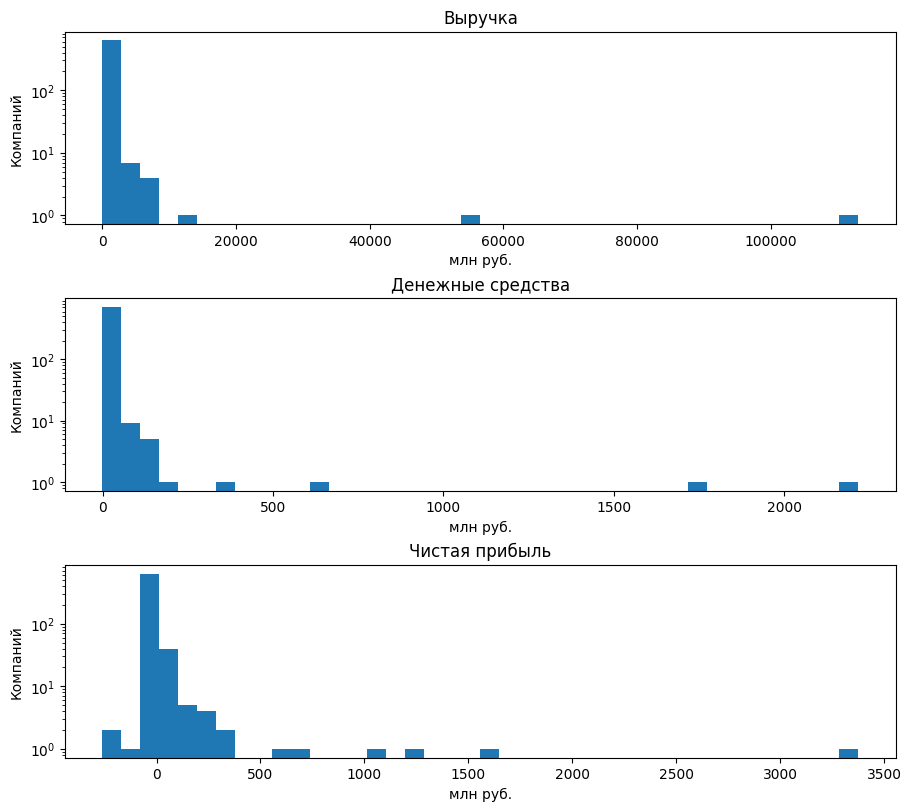

In [4]:
columns = ["Выручка", "Денежные средства", "Чистая прибыль"]
fig, axes = plt.subplots(3, 1, figsize=(9, 8), layout="constrained")
for name, ax in zip(columns, axes):
    ax.hist(df[name].dropna() / 1000, bins=40, log=True)
    ax.set(title=name, xlabel="млн руб.", ylabel="Компаний")
plt.show()

In [5]:
# Считаем значения за границами полутора межквартильных размахов
for name in columns:
    s = df[name].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    margin = 1.5 * (q3 - q1)
    outside = (s < q1 - margin) | (s > q3 + margin)
    print(name, "— выбросов:", outside.sum(), "из", len(s), "| ниже нуля:", (s < 0).sum())

Выручка — выбросов: 102 из 641 | ниже нуля: 0
Денежные средства — выбросов: 117 из 730 | ниже нуля: 2
Чистая прибыль — выбросов: 150 из 686 | ниже нуля: 136


У выручки длинный "правый хвост". Верхнюю границу пересекли 102 из 641 компаний с указанной выручкой. У денежных средств 117 выбросов, а у чистой прибыли 150. Отрицательная чистая прибыль у 136 из 686 компаний, т.е. убыток.

## 3. Корреляция между 20 показателями

Для каждой пары берём строки, где заполнены оба показателя. Сильной считаем связь с коэффициентом Пирсона от 0,9 по модулю.

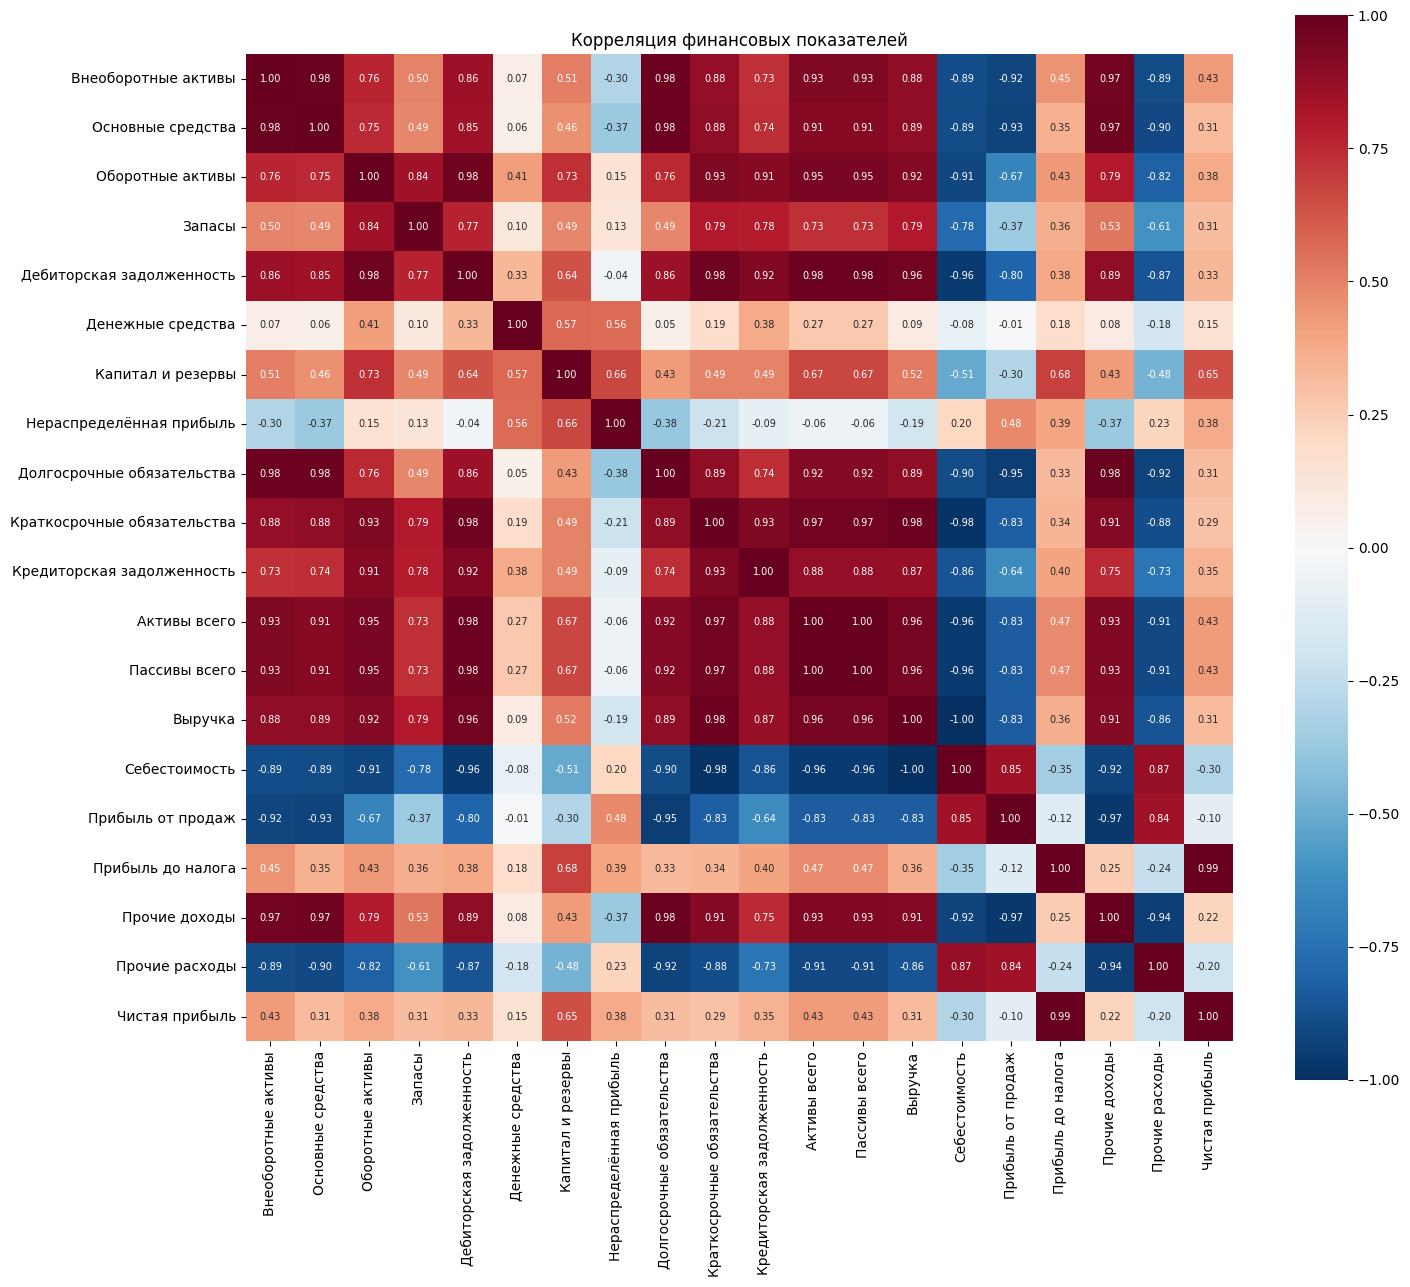

In [6]:
corr = df.corr()
plt.figure(figsize=(15, 13))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7}, square=True)
plt.title("Корреляция финансовых показателей")
plt.tight_layout()
plt.show()

In [7]:
# Каждую пару выводим один раз
for i, name in enumerate(corr.columns):
    for other in corr.columns[:i]:
        r = corr.loc[name, other]
        if abs(r) >= 0.9:
            print(f"{name} / {other}: {r:.3f}")

Основные средства / Внеоборотные активы: 0.985
Дебиторская задолженность / Оборотные активы: 0.976
Долгосрочные обязательства / Внеоборотные активы: 0.983
Долгосрочные обязательства / Основные средства: 0.978
Краткосрочные обязательства / Оборотные активы: 0.932
Краткосрочные обязательства / Дебиторская задолженность: 0.976
Кредиторская задолженность / Оборотные активы: 0.907
Кредиторская задолженность / Дебиторская задолженность: 0.923
Кредиторская задолженность / Краткосрочные обязательства: 0.932
Активы всего / Внеоборотные активы: 0.930
Активы всего / Основные средства: 0.914
Активы всего / Оборотные активы: 0.948
Активы всего / Дебиторская задолженность: 0.980
Активы всего / Долгосрочные обязательства: 0.917
Активы всего / Краткосрочные обязательства: 0.965
Пассивы всего / Внеоборотные активы: 0.930
Пассивы всего / Основные средства: 0.914
Пассивы всего / Оборотные активы: 0.948
Пассивы всего / Дебиторская задолженность: 0.980
Пассивы всего / Долгосрочные обязательства: 0.917
Пасс

У актива и пассива коэффициент округляется до 1. Это две стороны одного баланса, поэтому их итоги должны совпадать. Проверим равенство самих сумм.

In [8]:
balance = df[["Активы всего", "Пассивы всего"]].dropna()
difference = balance["Активы всего"] - balance["Пассивы всего"]
print("Заполнены обе статьи:", len(balance))
print("Совпали:", (difference == 0).sum())
balance.loc[difference != 0]

Заполнены обе статьи: 826
Совпали: 825


,Активы всего,Пассивы всего
723,70022.0,29562.0


Из 826 балансов со значениями по обеим статьям сошлись 825. В оставшемся актив превышает пассив на 40 460 тыс. руб. (70 022-29 562) Округлённый коэффициент корреляции скрыл это расхождение.

## 4. Выручка и себестоимость

В RFSD себестоимость записана со знаком минус. На втором графике увеличим область до 95-го процентиля выручки.

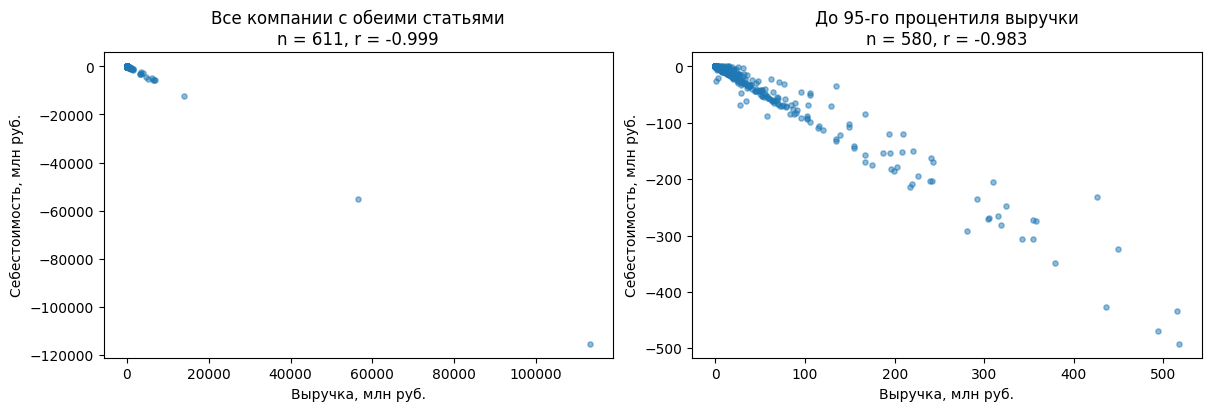

In [9]:
pair = df[["Выручка", "Себестоимость"]].dropna() / 1000
zoom = pair[pair["Выручка"] <= pair["Выручка"].quantile(0.95)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for data, ax, title in zip([pair, zoom], axes, ["Все компании с обеими статьями", "До 95-го процентиля выручки"]):
    ax.scatter(data["Выручка"], data["Себестоимость"], s=14, alpha=0.5)
    ax.set(title=title, xlabel="Выручка, млн руб.", ylabel="Себестоимость, млн руб.")
    r = data["Выручка"].corr(data["Себестоимость"])
    ax.set_title(f"{title}\nn = {len(data)}, r = {r:.3f}")
plt.show()

## 5. Выводы

1. По 611 компаниям с обеими статьями связь выручки и себестоимости почти линейная (r = -0,999). Если взять только компании с выручкой до 95-го процентиля, r = -0,983. На увеличенном графике виден разброс затрат при похожих оборотах.
2. Медианная чистая прибыль положительная (123,5 тыс. руб.), хотя примерно каждая пятая компания, указавшая результат, закончила год с убытком (136 / 686 * 100 = 19,8 %).